In [ ]:
import os 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('../figures', exist_ok=True)

col_skill = "#1f77b4"
col_knowledge = "#ff7f0e"

df = pd.read_parquet("../data/df_cleaned.parquet")

print(f"Data type of tags_skill: {type(df['tags_skill'].iloc[0])}")

Data type of tags_skill: <class 'numpy.ndarray'>


###  Average spans for skills and knowledge per sentences

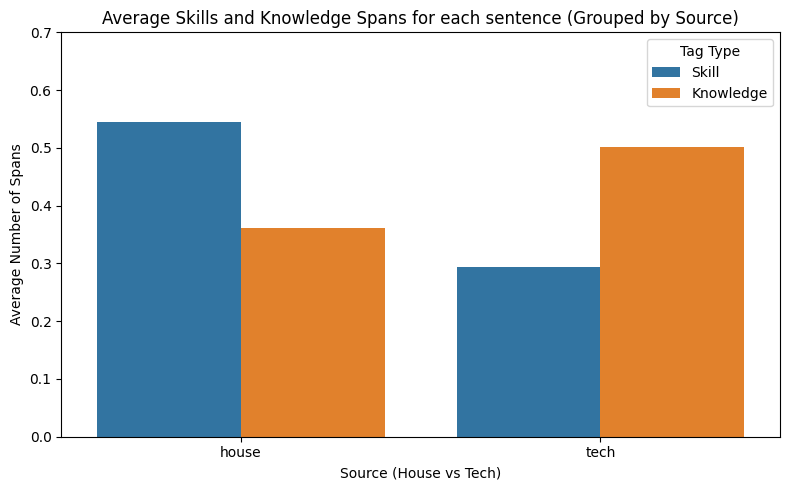

In [ ]:
avg_spans = df.groupby('source')[['num_skills','num_knowledge']].mean().reset_index()

avg_melted = avg_spans.melt(
    id_vars="source",
    value_vars=["num_skills", "num_knowledge"],
    var_name='Tag Type',
    value_name='Average Spans'
)

avg_melted['Tag Type'] = avg_melted['Tag Type'].replace({
    'num_skills' : 'Skill',
    'num_knowledge': "Knowledge"
})

plt.figure(figsize=(8,5))
ax = sns.barplot(
    data = avg_melted,
    x = 'source',
    y ='Average Spans',
    hue ='Tag Type',
    palette={'Skill': col_skill, "Knowledge": col_knowledge}
)

plt.title("Average Skills and Knowledge Spans for each sentence (Grouped by Source)")
plt.xlabel("Source (House vs Tech)")
plt.ylabel("Average Number of Spans")
plt.ylim(0, 0.7)

plt.tight_layout()
plt.savefig("../figures/01_avg_spans_per_sentence_by_source.png")
plt.show()

#### **From visualization**

Tech documents contain roughly 40% more knowledge spans per sentence (0.50 vs 0.36), while house documents are heavily skewed toward skill spans (0.54 vs 0.29)

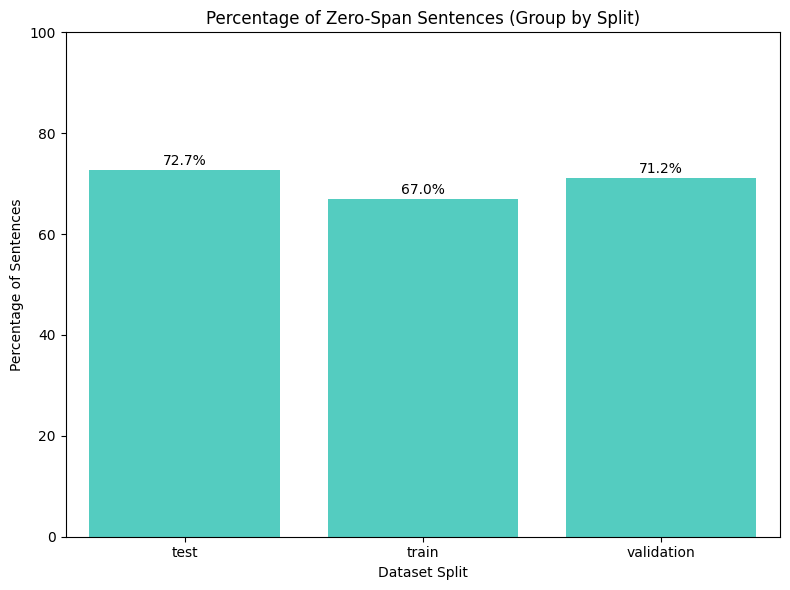

In [ ]:
df['has_no_span'] = (df['num_skills'] == 0) & (df['num_knowledge'] == 0)

# group by split
zero_span_pct = (df.groupby('split')['has_no_span'].mean() * 100).reset_index()

# visualizing

plt.figure(figsize=(8,6))
sns.barplot(
    data = zero_span_pct,
    x = 'split',
    y = 'has_no_span',
    color= "#40e0d0"
)

plt.title("Percentage of Zero-Span Sentences (Group by Split)")
plt.xlabel("Dataset Split")
plt.ylabel("Percentage of Sentences")
plt.ylim(0,100)

for index, row in zero_span_pct.iterrows():
    plt.text(index, row.has_no_span + 1, f"{row.has_no_span:.1f}%", color='black', ha="center")

plt.tight_layout()
plt.savefig("../figures/02_zero_span_percentage_by_split.png")
plt.show()

**Interpretation**
- The training set is denser (67.0% empty) than the test set (72.7% empty). This class imbalance partly explains why the training set averages more spans per sentence, though the training sentences that do contain spans are likely denser as well.

###  Visualizing Span Length

In [9]:
def get_span_length(row):
    length = []
    current_length = 0

    for tag in row:
        if tag.startswith("B"):
            if current_length > 0:
                length.append(current_length)
            current_length = 1
        elif tag.startswith("I") and current_length > 0:
            current_length += 1
        else:
            if current_length > 0:
                length.append(current_length)
                current_length = 0

    if current_length > 0:
        length.append(current_length)
    return length

In [11]:
skill_length = df['tags_skill'].apply(get_span_length).explode().dropna().astype(int)
knowledge_length = df['tags_knowledge'].apply(get_span_length).explode().dropna().astype(int)

length_df = pd.DataFrame({
    'Span Length': pd.concat([skill_length,knowledge_length]),
    'Tag Type': ['Skill'] * len(skill_length) + ['Knowledge'] * len(knowledge_length)
})


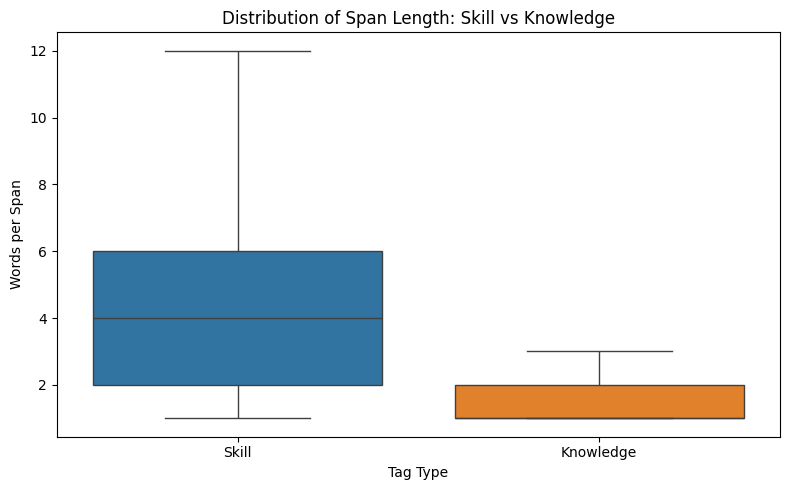

Median Skill Length: 4.0
Median Knowledge Length: 1.0


In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data = length_df,
    x = 'Tag Type',
    y = "Span Length",
    hue = "Tag Type",
    palette={"Skill": col_skill, "Knowledge": col_knowledge},
    legend= False,
    showfliers = False
)

plt.title("Distribution of Span Length: Skill vs Knowledge")
plt.xlabel("Tag Type")
plt.ylabel("Words per Span")

plt.tight_layout()
plt.savefig("../figures/03_span_length_distribution.png")
plt.show()

print(f"Median Skill Length: {skill_length.median()}")
print(f"Median Knowledge Length: {knowledge_length.median()}")

Knowledge spans are highly concise (median 1 word, mostly ranging from 1 to 2 words), whereas skill spans are more descriptive and longer (median 4 words, typically ranging from 2 to 6 words).

#### Record the Top Frequent Skills and Knowledge

In [17]:
def get_span_tag(row, tag_column):
    tokens = row['tokens']
    tags = row[tag_column]

    spans = []
    current_span = []

    for token, tag in zip(tokens, tags):
        if tag.startswith('B'):     # starts with B tag
            if current_span:
                spans.append(" ".join(current_span))    # Save the previous span
            current_span = [token]  # start with a new span

        elif tag.startswith('I') and current_span:
            current_span.append(token)
        else:   #O tag
            if current_span:
                spans.append(" ".join(current_span))
                current_span=[]

    if current_span:
        spans.append(" ".join(current_span))

    return spans

In [18]:
skill_text = df.apply(lambda row: get_span_tag(row,'tags_skill'), axis = 1).explode().dropna()
knowledge_text = df.apply(lambda row: get_span_tag(row,'tags_knowledge'), axis = 1).explode().dropna()

top_skill = skill_text.value_counts().head(20)
top_knowledge = knowledge_text.value_counts().head(20)

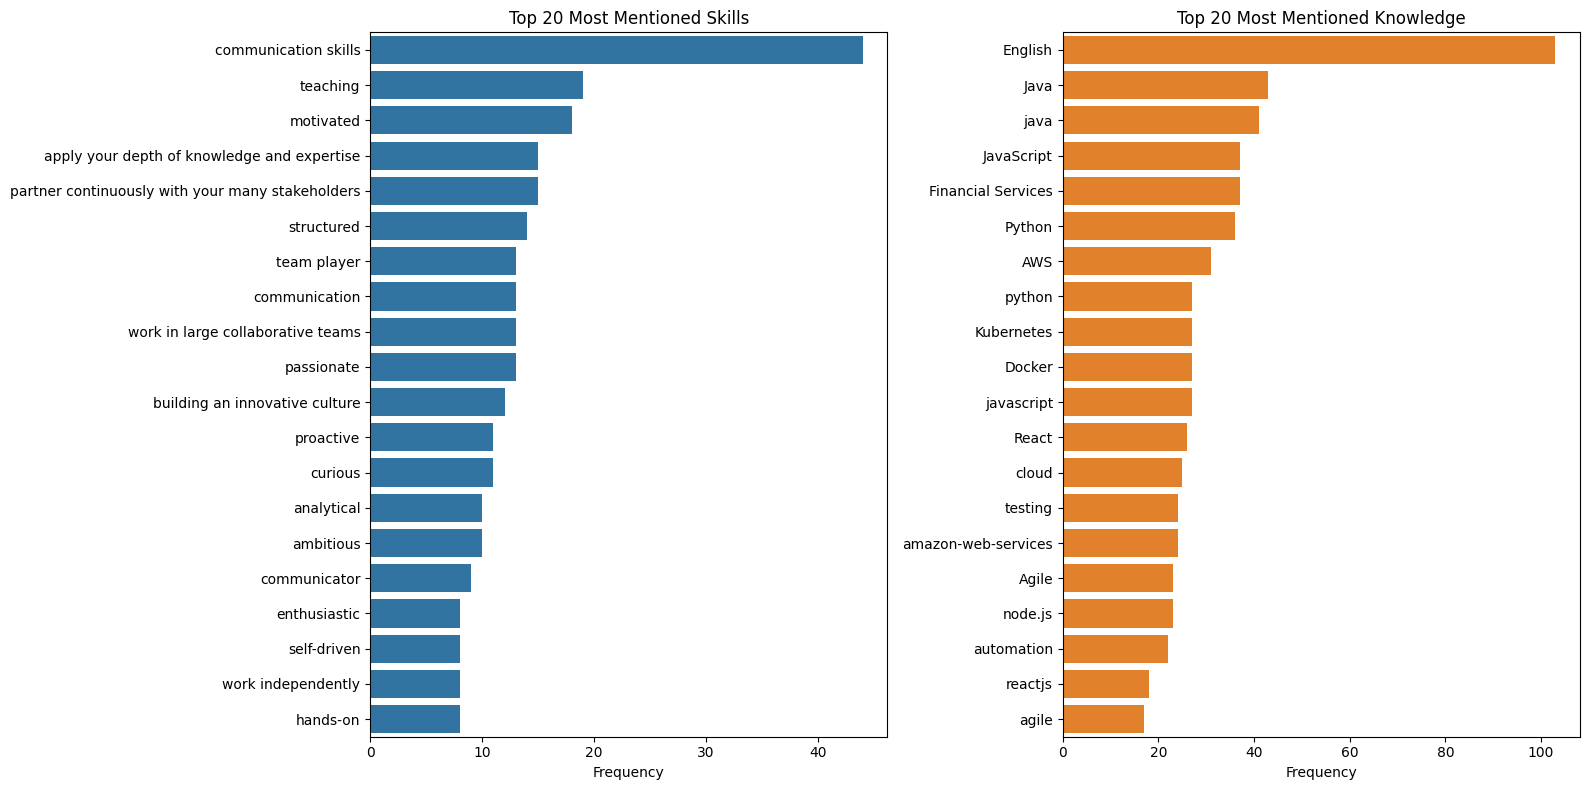

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(16,8))

# barplot for skills
sns.barplot(x = top_skill.values, y= top_skill.index, ax = axs[0], color= col_skill)
axs[0].set_title("Top 20 Most Mentioned Skills")
axs[0].set_xlabel("Frequency")
axs[0].set_ylabel("")

# barplot for knowledge
sns.barplot(x = top_knowledge.values, y= top_knowledge.index, ax = axs[1], color= col_knowledge)
axs[1].set_title("Top 20 Most Mentioned Knowledge")
axs[1].set_xlabel("Frequency")
axs[1].set_ylabel("")

plt.tight_layout()
plt.savefig("../figures/04_most_common_spans.png")
plt.show()

- Communication and English are the most universally requested skill and knowledge entities. The knowledge tags heavily feature specific technologies (e.g., Python, AWS, Docker), though frequency counts are fragmented by casing and abbreviation variations (e.g., "Java" vs. "java", "AWS" vs. "amazon-web-services").
- Some of the skills listed can be lengthy to be effectively map into distinct skills, I may try to parse the skill through an LLM model with a promt: "categorize the skills into the provided list of standard skills"

#### Sentence length distribution

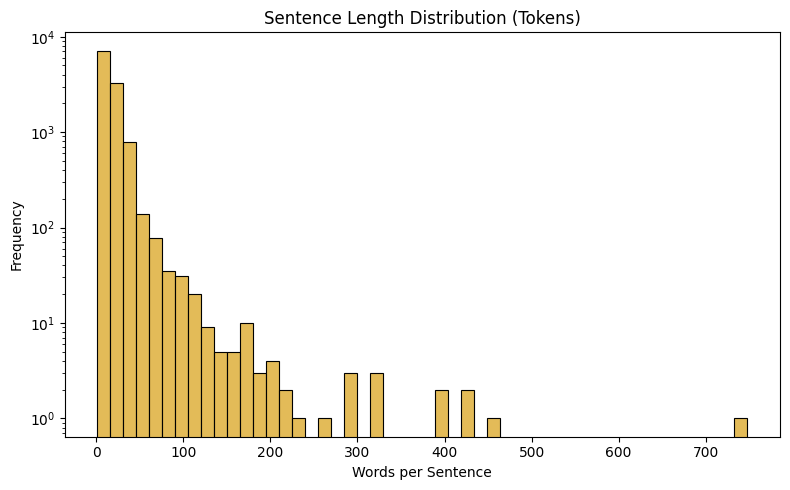

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['tokens_length'], bins= 50, color="#DAA520")

plt.title("Sentence Length Distribution (Tokens)")
plt.xlabel("Words per Sentence")
plt.ylabel("Frequency")

plt.yscale('log')

plt.tight_layout()
plt.savefig("../figures/05_token_length_distribution.png")
plt.show()

Most sentences are short (median 11 words), but the distribution has a long tail (heavily right-skewed)

In [31]:
df['sentence_text'] = df['tokens'].apply(lambda x: " ".join(x))

total_dupes = df.duplicated(subset=['sentence_text']).sum()
print(f"Total duplicate sentences in dataset: {total_dupes}")

train_sentences = set(df[df['split'] == 'train']['sentence_text'])
test_sentences = set(df[df['split'] == 'test']['sentence_text'])

overlap = train_sentences.intersection(test_sentences)
print(f"Sentences in BOTH train and test sets: {len(overlap)}")

# Clean up
df = df.drop(columns=['sentence_text'])

Total duplicate sentences in dataset: 2708
Sentences in BOTH train and test sets: 174


The dataset has significant boilerplate repetition (2,708 duplicate sentences), including 174 exact sentence overlaps between the training and test sets. This data leakage is preserved to maintain the official benchmark split but should be noted as a source of slight metric inflation during evaluation.